# CausalPFN baseline on Criteo Uplift v2.1, 50,000 rows

Run all cells to draw a stratified sample of 50,000 rows from Criteo Uplift v2.1, run CausalPFN and four comparison methods, and display the fold log, normalized Qini comparison, and Qini curves.

The paper's historical scikit-uplift archive returned HTTP 404. This run uses the checksum-verified full v2.1 release as its sampling frame. Table 2 gives reference scores on the authors' sample. The [Criteo report](../reports/baseline_results/criteo.md) also includes our separate 2.5-million-row run on v2.1.

## 0. Setup

Use the pinned dependencies in [baseline/requirements.txt](../baseline/requirements.txt) and a CUDA GPU. Download the [official Criteo v2.1 archive](https://huggingface.co/datasets/criteo/criteo-uplift/blob/main/criteo-research-uplift-v2.1.csv.gz) and save it as data/criteo-v21-source/criteo.csv.gz. Set CRITEO_V21_DATA_DIR to use the archive from a different folder. Set CAUSALPFN_CHECKPOINT to use a local copy of the published checkpoint.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# Works when opened from the repo's notebooks/ folder (local Jupyter, college server)
# and on Colab/Kaggle, where it clones the repo first.
BRANCH = "baseline-reproduction"
here = Path.cwd()
if (here / "baseline").exists():
    REPO = here
elif (here.parent / "baseline").exists():
    REPO = here.parent
else:
    REPO = Path("/content" if os.path.exists("/content") else here) / "causal-uplift-engine"
    if not REPO.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--recurse-submodules",
                "-b",
                BRANCH,
                "https://github.com/yashashree5/causal-uplift-engine.git",
                str(REPO),
            ],
            check=True,
        )

if not (REPO / "third_party" / "CausalPFN" / "benchmarks").exists():
    subprocess.run(["git", "submodule", "update", "--init", "--recursive"], cwd=REPO, check=True)

os.chdir(REPO)
sys.path.insert(0, str(REPO))
print("Project: causal-uplift-engine")
print("Python:", sys.version.split()[0])
if not ((3, 10) <= sys.version_info[:2] <= (3, 12)):
    print("WARNING: use Python 3.10 (authors' version); 3.11-3.12 usually work, 3.13 does not.")

Project: causal-uplift-engine
Python: 3.10.19


In [2]:
# Run once per environment. On Colab/Kaggle, restart the kernel after this cell, then run from step 1 again.
INSTALL = False  # set to True the first time
if INSTALL:
    get_ipython().run_line_magic("pip", "install -q -r baseline/requirements.txt")

## 1. GPU check

In [3]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("Enable a CUDA GPU to run this benchmark.")

DEVICE = "cuda:0"
gpu = torch.cuda.get_device_properties(0)
print(f"GPU: {gpu.name}, {gpu.total_memory / 1e9:.1f} GB")

GPU: NVIDIA GeForce RTX 4080 SUPER, 17.2 GB


## 2. Settings

The run uses its own folder under outputs/. Set CRITEO_50K_OUTPUT_DIR for a specific destination. Use a new destination for a fresh run.

In [4]:
from datetime import datetime, timezone

TASK = "criteo_sub50k"
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
output_setting = os.getenv("CRITEO_50K_OUTPUT_DIR")
OUTPUT_DIR = (
    Path(output_setting).expanduser()
    if output_setting
    else REPO / "outputs" / f"criteo-50k-notebook-{stamp}"
)
if (OUTPUT_DIR / "predictions").exists():
    raise FileExistsError("Choose a fresh CRITEO_50K_OUTPUT_DIR for this run.")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Run folder: {OUTPUT_DIR.name}")

Run folder: criteo-50k


## 3. Verify v2.1 and form the five folds

The scikit-uplift loader checks the MD5 of the full v2.1 archive. The pinned CausalPFN dataset code then samples 50,000 rows and assigns five test folds, stratified by randomized treatment and visit outcome with root seed 82718.

In [5]:
from unittest.mock import patch

from sklift.datasets import fetch_criteo

from baseline import authors
from baseline.tasks import build

archive_dir = Path(os.getenv("CRITEO_V21_DATA_DIR", REPO / "data" / "criteo-v21-source")).expanduser()
if not (archive_dir / "criteo.csv.gz").is_file():
    raise FileNotFoundError(
        "Save the official v2.1 archive as criteo.csv.gz in CRITEO_V21_DATA_DIR or data/criteo-v21-source."
    )

def load_v21(*, treatment_col, target_col, percent10):
    return fetch_criteo(
        treatment_col=treatment_col,
        target_col=target_col,
        data_home=archive_dir,
        download_if_missing=False,
        percent10=False,
    )

authors.datasets()
with patch("benchmarks.criteo.fetch_criteo", new=load_v21):
    cohort = build(TASK)
fold_sizes = [len(indices) for indices in cohort.all_fold_test_idx]
if len(cohort.all_X) != 50_000 or fold_sizes != [10_000] * 5:
    raise ValueError("The benchmark requires exactly 50,000 rows and five 10,000-row test folds.")
print("Criteo Uplift v2.1 archive checksum verified by scikit-uplift.")
print(f"Sample: {len(cohort.all_X):,} rows, {cohort.all_X.shape[1]} features")
print(f"Treated: {cohort.all_t.mean():.3%}, visits: {cohort.all_y.mean():.3%}")
print(f"Test fold sizes: {fold_sizes}")

<workspace>\hillstrom-causalpfn\.venv-paper\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Criteo Uplift v2.1 archive checksum verified by scikit-uplift.
Sample: 50,000 rows, 12 features
Treated: 85.000%, visits: 4.700%
Test fold sizes: [10000, 10000, 10000, 10000, 10000]


## 4. Run CausalPFN and the four comparison methods

The fold log below records each held-out prediction run and its wall time.

In [6]:
import hashlib
from functools import partial
from time import perf_counter

from baseline import run

checkpoint_setting = os.getenv("CAUSALPFN_CHECKPOINT")
factory = authors.cate_estimator
if checkpoint_setting:
    checkpoint = Path(checkpoint_setting).expanduser()
    expected_sha256 = "4f0f53717f1c62426fe98faa0459d33bc8f9862a87e8484ca3869ca899e7841d"
    if hashlib.sha256(checkpoint.read_bytes()).hexdigest() != expected_sha256:
        raise ValueError("The local CausalPFN checkpoint failed SHA-256 verification.")
    def factory():
        return partial(estimator_class, model_path=str(checkpoint))
    estimator_class = authors.cate_estimator()
    print("Published CausalPFN checkpoint checksum verified.")

revision = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"], cwd=authors.ROOT, text=True
).strip()
if revision != authors.PINNED_COMMIT:
    raise RuntimeError(f"Use the pinned CausalPFN revision {authors.PINNED_COMMIT}, found {revision}.")
print(f"CausalPFN source revision: {revision}")
run._set_seeds()
started = perf_counter()
with patch.object(run, "build", return_value=cohort), patch.object(authors, "cate_estimator", new=factory):
    run.run_task(TASK, run.METHODS, OUTPUT_DIR, DEVICE)
benchmark_seconds = perf_counter() - started
print(f"Benchmark elapsed: {benchmark_seconds:.1f} seconds")

Published CausalPFN checkpoint checksum verified.
CausalPFN source revision: 7da4afa

=== criteo_sub50k ===


rows=50,000 treated=0.850 outcome_rate=0.0470


1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:455.)


causalpfn  fold 0  n_test=10,000  21s


causalpfn  fold 1  n_test=10,000  21s


causalpfn  fold 2  n_test=10,000  24s


... (19 outputs left out)

t_learner  fold 2  n_test=10,000  0s


t_learner  fold 3  n_test=10,000  0s


t_learner  fold 4  n_test=10,000  0s


Benchmark elapsed: 124.6 seconds


## 5. Metrics compared with Table 2

Qini is computed from pooled held-out predictions. Normalized Qini divides each method's score by the best method on this cohort. The paper column is a reference from the authors' cohort.

In the completed run below, the S-learner predicted zero uplift for 47,676 of 50,000 rows. Its Qini depends on how the scoring code orders those tied rows. The [Criteo report](../reports/baseline_results/criteo.md#tied-uplift-predictions) documents the tie checks for both sample sizes.

In [7]:
from IPython.display import display

from baseline.evaluate import score_task

scores = score_task(OUTPUT_DIR, TASK)
if set(scores["method"]) != set(run.METHODS) or not scores["n_test_rows"].eq(50_000).all():
    raise RuntimeError("Each of the five methods must have 50,000 held-out predictions.")
REPORTS = OUTPUT_DIR / "reports"
REPORTS.mkdir(exist_ok=True)
scores = scores.drop(columns=["within_tolerance"])
scores["data_variant"] = "criteo_v21_stratified_50k"
scores["benchmark_seconds"] = benchmark_seconds
scores.to_csv(REPORTS / "baseline_criteo.csv", index=False)
columns = {
    "method": "Method", "qini_raw": "Qini", "qini_normalized": "Normalized Qini",
    "paper_normalized": "Table 2 reference", "difference": "Difference", "n_test_rows": "Held-out rows",
}
display(scores[list(columns)].rename(columns=columns).round(6).reset_index(drop=True))

,Method,Qini,Normalized Qini,Table 2 reference,Difference,Held-out rows
0,x_learner,0.767801,1.000000,1.000,0.000000,50000
1,da_learner,0.767416,0.999499,0.626,0.373499,50000
2,t_learner,0.720935,0.938960,0.701,0.237960,50000
3,causalpfn,0.646180,0.841598,0.859,-0.017402,50000
4,s_learner,0.434844,0.566349,0.881,-0.314651,50000


## 6. Qini curves

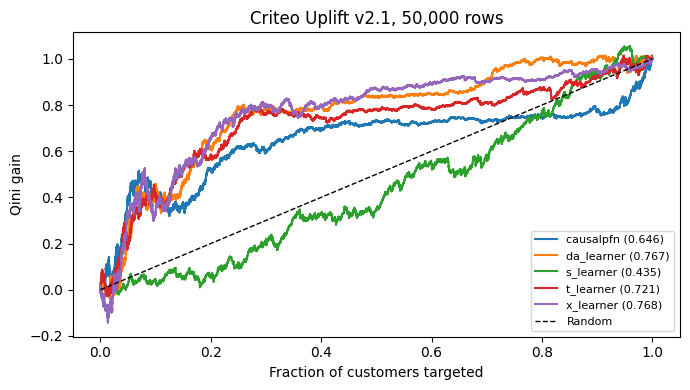

In [8]:
import matplotlib.pyplot as plt
import numpy as np

from baseline.evaluate import load
from eval.qini import get_qini_curve

fig, ax = plt.subplots(figsize=(7, 4))
for method, predictions in load(OUTPUT_DIR, TASK).items():
    curve, qini = get_qini_curve(
        predictions["t"].to_numpy(float),
        predictions["y"].to_numpy(float),
        predictions["uplift_pred"].to_numpy(float),
    )
    ax.plot(np.linspace(0, 1, len(curve)), curve, label=f"{method} ({qini:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
ax.set(xlabel="Fraction of customers targeted", ylabel="Qini gain", title="Criteo Uplift v2.1, 50,000 rows")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(REPORTS / "qini_criteo.png", dpi=150)
plt.show()

The [Criteo benchmark report](../reports/baseline_results/criteo.md) records these metrics alongside our separately executed 2.5-million-row v2.1 benchmark.